# Flight Delay Analysis and Prediction (Python)

Analysis of US domestic flights 2004–2008 (ASA Data Expo 2009). See the repo README for context and results.

This is the original coursework notebook, kept with its saved outputs. Two things to know before reading:

- **Q5 contains target leakage.** Its models use features that are only known after departure, so their AUCs (0.94–0.98) are inflated. The leakage-free version is `src/model_v2.py`; see Q5b at the end.
- The cells were run across several sessions (see the execution counts), so the saved outputs are not from a single top-to-bottom run.

In [1]:
import os
import sqlite3
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib as mpl
import datetime
import plotly.express as px
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import train_test_split, GridSearchCV      
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [2]:
# Point DATA_DIR at the folder holding the downloaded CSVs (see data/README.md)
DATA_DIR = '../data'
os.chdir(DATA_DIR)

In [3]:
try:
    os.remove('Fly.db')
except OSError:
    pass

conn = sqlite3.connect('Fly.db')

In [5]:
pd.read_csv("airports.csv").to_sql("airports", conn, if_exists="replace", index=False)
pd.read_csv("carriers.csv").to_sql("carriers", conn, if_exists="replace", index=False)
pd.read_csv("plane-data.csv").to_sql("planes", conn, if_exists="replace", index=False)

for year in range(2004, 2009):
    file_pattern = f"{year}*.csv*.bz2"
    file_list = glob.glob(file_pattern)
    
    if file_list:
        actual_file = file_list[0]
        print(f"Now processing: {actual_file}")
        
        flightdetails = pd.read_csv(actual_file, low_memory=False)
        flightdetails.to_sql("flightdetails", conn, if_exists="append", index=False)
    else:
        print(f"Warning: No file found for year {year}")

conn.close()
print("Database construction complete.")

Now processing: 2004.csv.bz2
Now processing: 2005.csv.bz2
Now processing: 2006.csv.bz2
Now processing: 2007.csv.bz2
Now processing: 2008.csv.bz2
Database construction complete.


In [6]:
ArrDelayModel = smf.ols('ArrDelay ~ CarrierDelay + WeatherDelay + NASDelay + SecurityDelay + LateAircraftDelay', data=flightdetails).fit()
DepDelayModel = smf.ols('DepDelay ~ CarrierDelay + WeatherDelay + NASDelay + SecurityDelay + LateAircraftDelay', data=flightdetails).fit()

print(ArrDelayModel.summary())
print(DepDelayModel.summary())

ArrDepDelay = pd.DataFrame({
'Measure': ['Arrival Delay', 'Departure Delay'],
'R2': [ArrDelayModel.rsquared, DepDelayModel.rsquared],
'Adjusted_R2': [ArrDelayModel.rsquared_adj, DepDelayModel.rsquared_adj],
'F_Statistic': [ArrDelayModel.fvalue, DepDelayModel.fvalue]
})

print(ArrDepDelay)

                            OLS Regression Results                            
Dep. Variable:               ArrDelay   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 5.450e+32
Date:                Tue, 31 Mar 2026   Prob (F-statistic):               0.00
Time:                        00:58:45   Log-Likelihood:             1.5439e+07
No. Observations:              584583   AIC:                        -3.088e+07
Df Residuals:                  584577   BIC:                        -3.088e+07
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          3.011e-13   1.54e-1

**What this regression does and does not show.** The five cause columns (carrier, weather, NAS, security, late aircraft) are the airline's own breakdown of each delay, so they add up to it by definition and are only filled in for delayed flights. The R² of 1.000 is therefore a consistency check on the data, not a finding about what causes delays.

Note also that `flightdetails` here is the DataFrame left in memory by the loading loop above, which is only the last file read (2008), not the full database.

In [7]:
with sqlite3.connect('Fly.db') as conn:
    query = """
    SELECT ArrDelay, COUNT(ArrDelay) AS Frequency 
    FROM flightdetails 
    WHERE ArrDelay > 0 
    GROUP BY ArrDelay
    """
    DistributionOfArrDelay = pd.read_sql(query, conn)

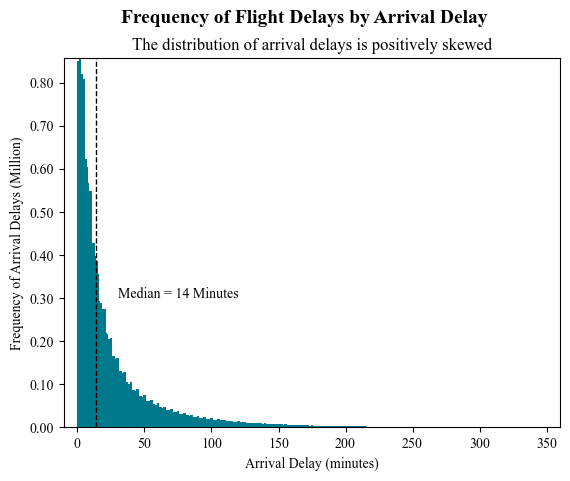

In [8]:
mpl.rcParams['font.family'] = 'Times New Roman'

plt.bar(DistributionOfArrDelay["ArrDelay"], DistributionOfArrDelay["Frequency"], color="#00798c", width=2)
plt.suptitle("Frequency of Flight Delays by Arrival Delay", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("The distribution of arrival delays is positively skewed", fontname='Times New Roman')
plt.xlabel("Arrival Delay (minutes)", fontname='Times New Roman')
plt.ylabel("Frequency of Arrival Delays (Million)", fontname='Times New Roman')
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
plt.xlim([-10, 360])
plt.ylim([0, DistributionOfArrDelay["Frequency"].max()])
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.2f}'.format(x*1e-6)))
plt.axvline(x=14, color='black', linewidth = 1, linestyle='--')
plt.annotate('Median = 14 Minutes', xy=(14, 14), xytext=(30, 300000), fontname='Times New Roman')
plt.show()

In [9]:
cur = conn.cursor()

cur.execute("""SELECT ArrDelay 
               FROM flightdetails 
               WHERE ArrDelay > 0""")

median_delay = np.median(cur.fetchall())

avg_delay = pd.read_sql_query("""SELECT AVG(ArrDelay) \
                                 FROM flightdetails \
                                 WHERE ArrDelay > 0""", conn)

print(median_delay)
print(avg_delay)

14.0
   AVG(ArrDelay)
0       29.55957


## Q1. Best time of the day to minimize delays

In [17]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN DepTimeOfDay TEXT")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET DepTimeOfDay = 
                     CASE 
                        WHEN DepTime BETWEEN 500 AND 1159 THEN 'Morning' 
                        WHEN DepTime BETWEEN 1200 AND 1659 THEN 'Afternoon' 
                        WHEN DepTime BETWEEN 1700 AND 2059 THEN 'Evening' 
                        ELSE 'Night' 
                     END;""")

conn.commit()

In [18]:
Q1_TimeOfDay = pd.read_sql_query("""SELECT DepTimeOfDay AS Time_of_Day, 
                                    SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay 
                                    FROM flightdetails
                                    GROUP BY DepTimeOfDay 
                                    ORDER BY 
                                        CASE DepTimeOfDay 
                                            WHEN 'Morning' THEN 1 
                                            WHEN 'Afternoon' THEN 2 
                                            WHEN 'Evening' THEN 3 
                                            ELSE 4 
                                        END""", conn)

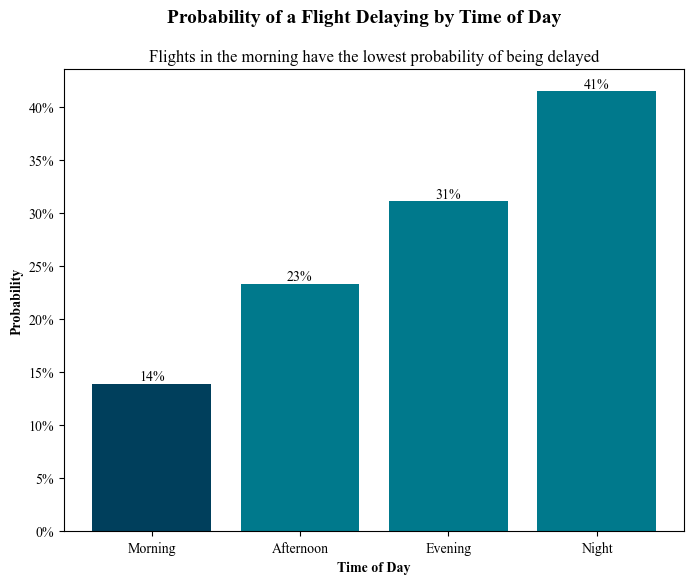

In [19]:
plt.figure(figsize=(8,6))
plt.bar(Q1_TimeOfDay['Time_of_Day'], Q1_TimeOfDay['Chance_Of_Delay'], color=['#003f5c', '#00798c', '#00798c', '#00798c'])
plt.suptitle("Probability of a Flight Delaying by Time of Day", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Flights in the morning have the lowest probability of being delayed", fontname='Times New Roman')
plt.xlabel("Time of Day", fontweight='bold', fontname='Times New Roman')
plt.ylabel("Probability", fontweight='bold', fontname='Times New Roman')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
for i, val in enumerate(Q1_TimeOfDay['Chance_Of_Delay']):
    plt.text(i, val, '{:.0%}'.format(val), ha='center', va='bottom', fontname='Times New Roman', fontsize=10)
plt.show()

## Q1. Best day of the week to minimize delays

In [20]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN FullDayOfWeek TEXT")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET FullDayOfWeek = 
                    CASE 
                        WHEN DayOfWeek IS 1 THEN 'Monday' 
                        WHEN DayOfWeek IS 2 THEN 'Tuesday' 
                        WHEN DayOfWeek IS 3 THEN 'Wednesday' 
                        WHEN DayOfWeek IS 4 THEN 'Thursday' 
                        WHEN DayOfWeek IS 5 THEN 'Friday' 
                        WHEN DayOfWeek IS 6 THEN 'Saturday' 
                        ELSE 'Sunday' 
                    END;""")

conn.commit()

In [21]:
Q1_DayOfWeek = pd.read_sql_query("""SELECT FullDayOfWeek AS Day_of_Week, 
                                    SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay 
                                    FROM flightdetails 
                                    GROUP BY FullDayOfWeek 
                                    ORDER BY 
                                        CASE FullDayOfWeek 
                                        WHEN 'Monday' THEN 1 
                                        WHEN 'Tuesday' THEN 2 
                                        WHEN 'Wednesday' THEN 3 
                                        WHEN 'Thursday' THEN 4 
                                        WHEN 'Friday' THEN 5 
                                        WHEN 'Saturday' THEN 6 
                                        ELSE 7 
                                    END""", conn)

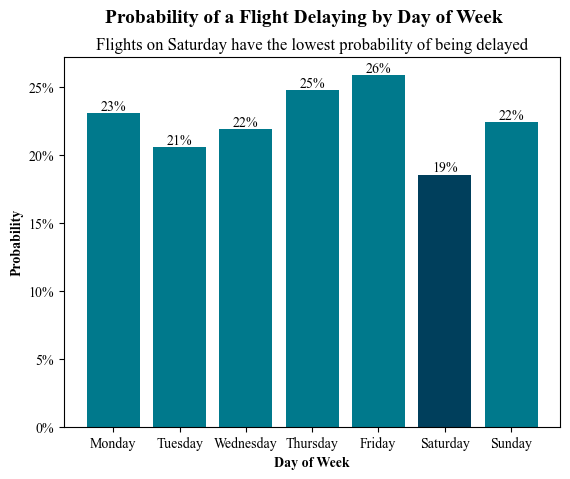

In [22]:
plt.bar(Q1_DayOfWeek['Day_of_Week'], Q1_DayOfWeek['Chance_Of_Delay'], color=['#00798c','#00798c','#00798c','#00798c','#00798c','#003f5c','#00798c'])
plt.suptitle("Probability of a Flight Delaying by Day of Week", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Flights on Saturday have the lowest probability of being delayed", fontname='Times New Roman')
plt.xlabel("Day of Week", fontweight='bold', fontname='Times New Roman')
plt.ylabel("Probability", fontweight='bold', fontname='Times New Roman')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
for i, val in enumerate(Q1_DayOfWeek['Chance_Of_Delay']):
    plt.text(i, val, '{:.0%}'.format(val), ha='center', va='bottom', fontname='Times New Roman', fontsize=10)
plt.show()

## Q1. Best time of the year to fly to minimize delays

In [23]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN TimeOfYear TEXT")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET TimeOfYear = 
                    CASE 
                        WHEN Month BETWEEN 3 AND 5 THEN 'Spring' 
                        WHEN Month BETWEEN 6 AND 8 THEN 'Summer' 
                        WHEN Month BETWEEN 9 AND 11 THEN 'Autumn' 
                        ELSE 'Winter' 
                    END;""")
             
conn.commit()            

In [24]:
Q1_TimeOfYear = pd.read_sql_query("""SELECT TimeOfYear AS Time_of_Year, 
                                    SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay 
                                    FROM flightdetails 
                                    GROUP BY TimeOfYear 
                                    ORDER BY 
                                        CASE TimeOfYear 
                                        WHEN 'Spring' THEN 1 
                                        WHEN 'Summer' THEN 2 
                                        WHEN 'Autumn' THEN 3 
                                        ELSE 4 
                                    END""", conn)

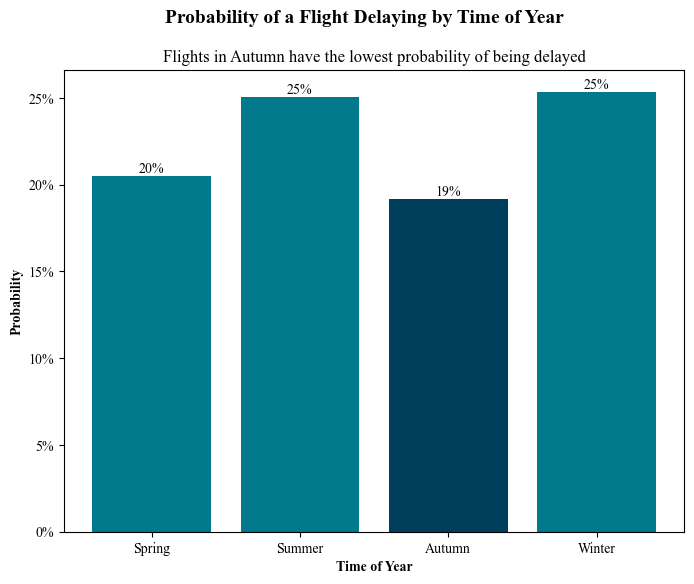

In [25]:
plt.figure(figsize=(8,6))
plt.bar(x = pd.Categorical(Q1_TimeOfYear['Time_of_Year'], categories=["Spring", "Summer", "Autumn", "Winter"], ordered=True), height=Q1_TimeOfYear['Chance_Of_Delay'], color=["#00798c", "#00798c", "#003f5c", "#00798c"])
plt.suptitle("Probability of a Flight Delaying by Time of Year", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Flights in Autumn have the lowest probability of being delayed", fontname='Times New Roman')
plt.xlabel("Time of Year", fontweight='bold', fontname='Times New Roman')
plt.ylabel("Probability", fontweight='bold', fontname='Times New Roman')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: '{:.0%}'.format(x)))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
for i, val in enumerate(Q1_TimeOfYear['Chance_Of_Delay']):
    plt.text(i, val, '{:.0%}'.format(val), ha='center', va='bottom', fontname='Times New Roman', fontsize=10)
plt.show()

## Q2. Do older planes suffer more delays?

In [9]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN CurrentDate INTEGER")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET CurrentDate = STRFTIME('%d/%m/%Y', Year || '-' || 
                    CASE WHEN LENGTH(Month) = 1 THEN '0' || Month 
                            ELSE Month
                    END || '-' || 
                    CASE WHEN LENGTH(DayofMonth) = 1 THEN '0' || DayofMonth 
                            ELSE DayofMonth 
                    END)""")

conn.commit()

In [10]:
conn.execute("ALTER TABLE flightdetails ADD COLUMN AgeOfPlane INTEGER")

conn.commit()

conn.execute("""UPDATE flightdetails 
                SET AgeOfPlane = 
                    CASE 
                        WHEN (julianday(strftime('%Y-%m-%d', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))) - julianday(strftime('%Y-%m-%d', planes.year || '-01-01')))/365 < 2000 THEN CAST(((julianday(strftime('%Y-%m-%d', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))) - julianday(strftime('%Y-%m-%d', planes.year || '-01-01')))/365) AS float) 
                        ELSE NULL 
                    END 
                FROM planes 
                WHERE flightdetails.TailNum = planes.tailnum""")

conn.commit()

In [11]:
check_join = pd.read_sql_query("""
    SELECT f.TailNum, p.tailnum as PlaneTableTail, p.year as MfgYear
    FROM flightdetails f
    LEFT JOIN planes p ON f.TailNum = p.tailnum
    LIMIT 10
""", conn)
print(check_join)

  TailNum PlaneTableTail  MfgYear
0  N805UA         N805UA   1998.0
1  N851UA         N851UA   2002.0
2  N436UA         N436UA   1996.0
3  N828UA         N828UA   1999.0
4  N831UA         N831UA   2000.0
5  N834UA         N834UA   2001.0
6  N840UA         N840UA   2001.0
7  N454UA         N454UA   1999.0
8  N808UA         N808UA   1998.0
9  N832UA         N832UA   2000.0


In [12]:
query = """
SELECT 
    f.TailNum, 
    f.Year as FlightYear, 
    p.year as MfgYear,
    (f.Year - CAST(p.year AS INT)) as CalculatedAge
FROM flightdetails f
INNER JOIN planes p ON f.TailNum = p.tailnum
WHERE (f.Year - CAST(p.year AS INT)) < 0
"""
AgeAbnormalities = pd.read_sql_query(query, conn)
print(f"Found {len(AgeAbnormalities)} abnormal rows.")

Found 5825 abnormal rows.


In [13]:
AgeAbnormalities = pd.read_sql_query("SELECT COUNT(flightdetails.AgeOfPlane) AS AgeLessZero, flightdetails.TailNum, planes.year \
                                     FROM flightdetails \
                                     INNER JOIN planes ON flightdetails.TailNum = planes.tailnum \
                                     WHERE flightdetails.AgeOfPlane < 0 \
                                     GROUP BY flightdetails.TailNum \
                                     ORDER BY flightdetails.TailNum", conn)

print(AgeAbnormalities)

Empty DataFrame
Columns: [AgeLessZero, TailNum, year]
Index: []


In [14]:
try:
    conn.execute("ALTER TABLE flightdetails ADD COLUMN AgeCategory")
    conn.commit()
    print("Column 'AgeCategory' added successfully.")
except sqlite3.OperationalError:
    print("Column 'AgeCategory' already exists. Skipping add step...")

conn.execute("""
    UPDATE flightdetails
    SET AgeCategory = 
        CASE 
            WHEN AgeOfPlane IS NULL THEN NULL
            WHEN AgeOfPlane BETWEEN -5 AND 10 THEN 'New Aircraft'
            WHEN AgeOfPlane > 10 AND AgeOfPlane <= 20 THEN 'Standard Aircraft'
            ELSE 'Old Aircraft' 
        END
""")

conn.commit()
print("Data updated successfully.")

Column 'AgeCategory' added successfully.
Data updated successfully.


In [15]:
check_counts = pd.read_sql_query("SELECT AgeCategory, COUNT(*) FROM flightdetails GROUP BY AgeCategory", conn)
print(check_counts)

  AgeCategory  COUNT(*)
0        None  31254220


In [16]:
conn.execute("CREATE INDEX IF NOT EXISTS idx_planes_tail ON planes(tailnum)")
conn.execute("CREATE INDEX IF NOT EXISTS idx_flights_tail ON flightdetails(TailNum)")
conn.commit()

In [17]:
conn.execute("""
UPDATE flightdetails
SET AgeOfPlane = Year - (
    SELECT CAST(planes.year AS INT)
    FROM planes
    WHERE planes.tailnum = flightdetails.TailNum
)
WHERE EXISTS (
    SELECT 1 FROM planes WHERE planes.tailnum = flightdetails.TailNum
)
""")
conn.commit()
print("AgeOfPlane column populated.")

AgeOfPlane column populated.


In [19]:
conn.execute("""
UPDATE flightdetails
SET AgeCategory = 
    CASE 
        WHEN AgeOfPlane IS NULL THEN 'Unknown'
        WHEN AgeOfPlane <= 10 THEN 'New Aircraft'
        WHEN AgeOfPlane > 10 AND AgeOfPlane <= 20 THEN 'Standard Aircraft'
        ELSE 'Old Aircraft' 
    END
""")
conn.commit()
print("AgeCategory categorization complete.")

AgeCategory categorization complete.


In [20]:
Q2_AgeOfPlane = pd.read_sql("""SELECT AgeCategory AS Age_Category, SUM(CASE WHEN ArrDelay >= 15 THEN 1 ELSE 0 END)/CAST(COUNT(ArrDelay) AS float) AS Chance_Of_Delay
                               FROM flightdetails
                               WHERE AgeCategory IS NOT NULL
                               GROUP BY AgeCategory
                               ORDER BY 
                                CASE WHEN AgeCategory = 'New Aircraft' THEN 1
                                    WHEN AgeCategory = 'Standard Aircraft' THEN 2
                                    WHEN AgeCategory = 'Old Aircraft' THEN 3
                                    ELSE 4
                                END""", conn)

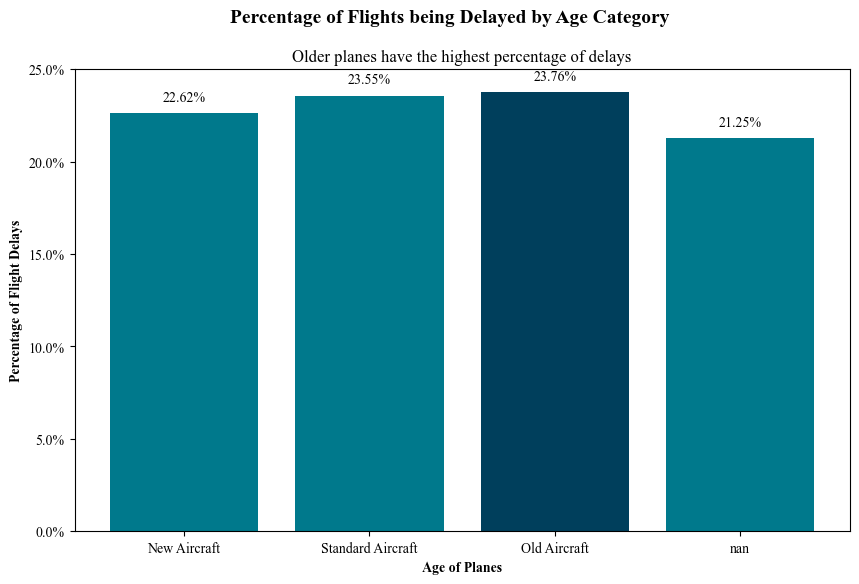

In [22]:
categories = ["New Aircraft", "Standard Aircraft", "Old Aircraft"]
Q2_AgeOfPlane['Age_Category'] = pd.Categorical(Q2_AgeOfPlane['Age_Category'], 
                                               categories=categories, 
                                               ordered=True)
df_plot = Q2_AgeOfPlane.sort_values('Age_Category')

fig, ax = plt.subplots(figsize=(10, 6))

x_pos = range(len(df_plot))
ax.bar(x_pos, df_plot['Chance_Of_Delay'], color=['#00798c', '#00798c', '#003f5c'])

plt.suptitle('Percentage of Flights being Delayed by Age Category', fontweight='bold', fontsize=14, fontname='Times New Roman')
plt.title('Older planes have the highest percentage of delays', fontname='Times New Roman')
plt.xlabel('Age of Planes', fontweight='bold', fontname='Times New Roman')
plt.ylabel('Percentage of Flight Delays', fontweight='bold', fontname='Times New Roman')

ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1))
plt.xticks(x_pos, df_plot['Age_Category'], fontname='Times New Roman')
plt.yticks(fontname='Times New Roman')
plt.ylim([0, 0.25])

for i, v in enumerate(df_plot['Chance_Of_Delay']):
    label = "{:.2%}".format(float(v))
    ax.text(i, float(v) + 0.005, label, ha='center', va='bottom', fontname='Times New Roman')

plt.show()

In [23]:
Q2_AgeOfPlane.head()

,Age_Category,Chance_Of_Delay
0,New Aircraft,0.226226
1,Standard Aircraft,0.235547
2,Old Aircraft,0.237614
3,NaN,0.212549


In [24]:
Q2_AgeOfPlaneDelays = pd.read_sql("""SELECT AgeCategory AS Age_Category, ArrDelay AS Duration_Of_Delays
                                     FROM flightdetails
                                     WHERE AgeCategory IS NOT NULL AND ArrDelay >= 15
                                     ORDER BY 
                                        CASE WHEN AgeCategory = 'New Aircraft' THEN 1
                                            WHEN AgeCategory = 'Standard Aircraft' THEN 2
                                            WHEN AgeCategory = 'Old Aircraft' THEN 3
                                            ELSE 4
                                        END""", conn)

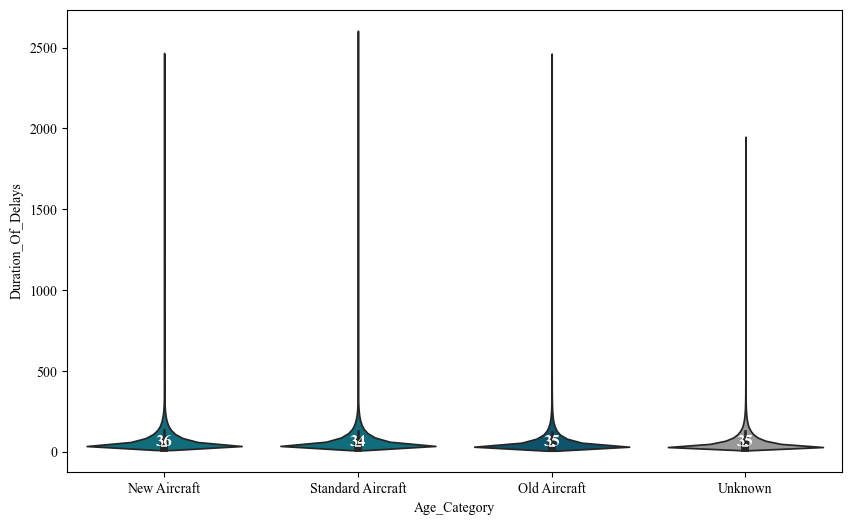

In [26]:
medians = Q2_AgeOfPlaneDelays.groupby(['Age_Category'])['Duration_Of_Delays'].median()

plt.figure(figsize=(10, 6))
ax = sns.violinplot(
    data=Q2_AgeOfPlaneDelays, 
    x='Age_Category', 
    y='Duration_Of_Delays', 
    hue='Age_Category', 
    legend=False,
    palette=['#00798c', '#00798c', '#005b7a', '#999999'],
    inner='box'
)

pos = range(len(medians))
for tick in pos:
    median_val = medians.iloc[tick]
    plt.text(
        tick, 
        median_val + 1, 
        str(int(median_val)), 
        horizontalalignment='center', 
        size='large', 
        color='white', 
        weight='semibold', 
        fontname='Times New Roman'
    )

plt.show()

## Q3. Number of people flying between different locations over time

In [53]:
Q3_MonthlyFrequencyIntrastate = pd.read_sql("""SELECT strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2)) AS Month, COUNT(*) as Frequency
                                               FROM flightdetails
                                               INNER JOIN airports ON flightdetails.Dest = airports.iata
                                               INNER JOIN airports a ON flightdetails.Origin = a.iata
                                               WHERE airports.state = a.state
                                               GROUP BY substr(flightdetails.CurrentDate, 4, 7)
                                               ORDER BY strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))""", conn)

In [58]:
Q3_MonthlyFrequencyInterstate = pd.read_sql("""SELECT strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2)) AS Month, COUNT(*) as Frequency
                                               FROM flightdetails
                                               INNER JOIN airports ON flightdetails.Dest = airports.iata
                                               INNER JOIN airports a ON flightdetails.Origin = a.iata
                                               WHERE airports.state <> a.state
                                               GROUP BY substr(flightdetails.CurrentDate, 4, 7)
                                               ORDER BY strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))""", conn)

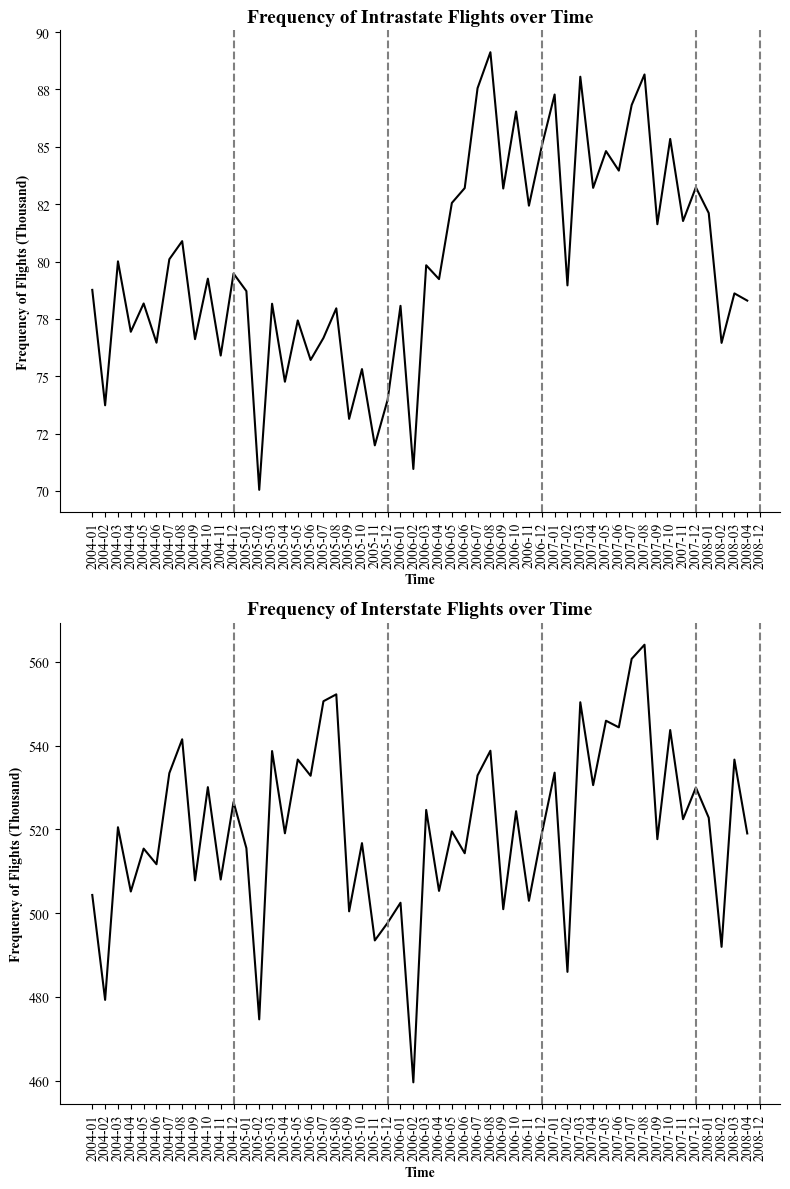

In [59]:
fig, axs = plt.subplots(nrows=2, figsize=(8, 12))

sns.lineplot(data=Q3_MonthlyFrequencyIntrastate, x='Month', y='Frequency', ax=axs[0], color='black')
sns.despine(ax=axs[0])
axs[0].set_title('Frequency of Intrastate Flights over Time', fontweight='bold', fontsize=14, fontname='Times New Roman')
axs[0].set_ylabel('Frequency of Flights (Thousand)', fontweight='bold', fontname='Times New Roman')
axs[0].set_xlabel('Time', fontweight='bold', fontname='Times New Roman')
axs[0].tick_params(axis='x', rotation=90)
axs[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    axs[0].axvline(x=xc, color='grey', linestyle='--')
    
sns.lineplot(data=Q3_MonthlyFrequencyInterstate, x='Month', y='Frequency', ax=axs[1], color='black')
sns.despine(ax=axs[1])
axs[1].set_title('Frequency of Interstate Flights over Time', fontweight='bold', fontsize=14, fontname='Times New Roman')
axs[1].set_ylabel('Frequency of Flights (Thousand)', fontweight='bold', fontname='Times New Roman')
axs[1].set_xlabel('Time', fontweight='bold', fontname='Times New Roman')
axs[1].tick_params(axis='x', rotation=90)
axs[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    axs[1].axvline(x=xc, color='grey', linestyle='--')   
    
plt.tight_layout()
plt.show()

In [56]:
Q3_MonthlyFrequencyOfIntrastateByState = pd.read_sql("""SELECT airports.state, strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2)) AS Month, COUNT() as Frequency, COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY substr(flightdetails.CurrentDate, 4, 7)) AS FLOAT) AS Percentage
                                                        FROM flightdetails
                                                        INNER JOIN airports ON flightdetails.Dest = airports.iata
                                                        INNER JOIN airports a ON flightdetails.Origin = a.iata
                                                        WHERE airports.state = a.state
                                                        GROUP BY airports.state, substr(flightdetails.CurrentDate, 4, 7)
                                                        ORDER BY strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))""", conn)

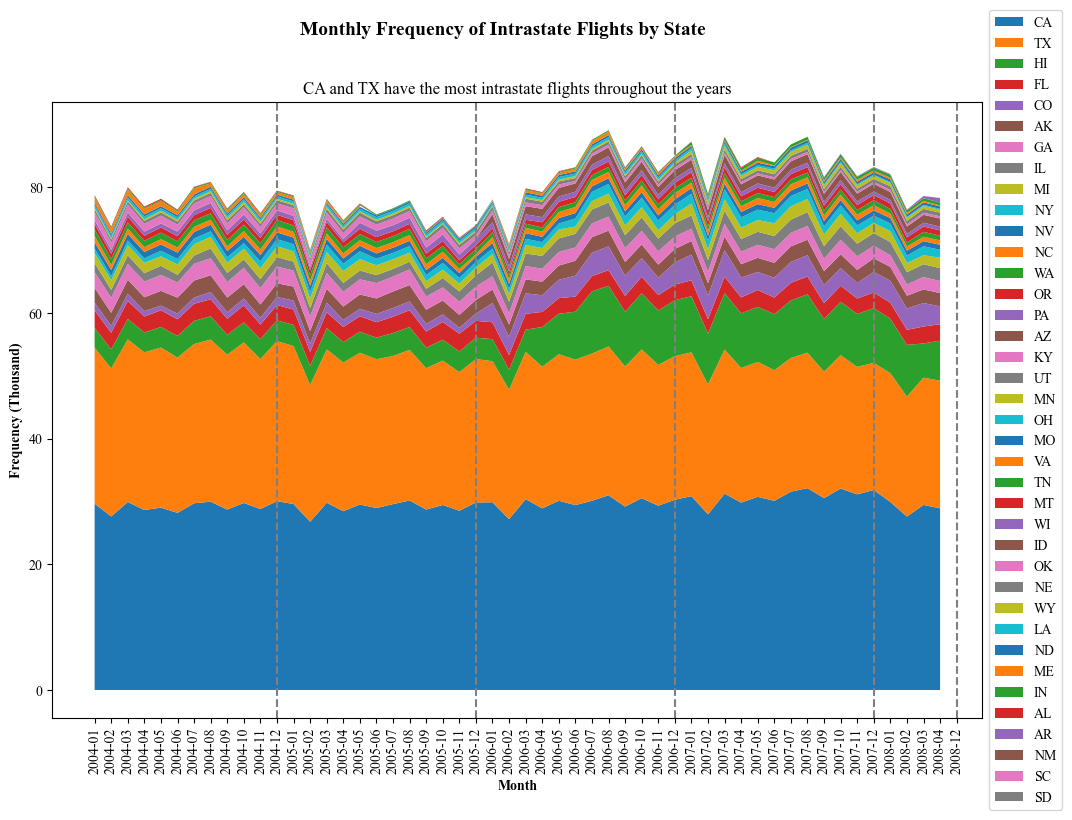

In [57]:
df = Q3_MonthlyFrequencyOfIntrastateByState.pivot_table(index='Month', columns='state', values='Frequency', aggfunc='sum')

state_order = df.sum().sort_values(ascending=False).index
df = df[state_order]
df_cumulative = df.cumsum(axis=1)
fig, ax = plt.subplots(figsize=(12,8))
for state in df.columns:
    ax.fill_between(df.index, df_cumulative[state] - df[state], df_cumulative[state], label=state, linewidth=0.5)
fig.suptitle('Monthly Frequency of Intrastate Flights by State', fontsize=14, fontweight='bold', fontname='Times New Roman')
ax.set_title('CA and TX have the most intrastate flights throughout the years', fontname='Times New Roman')
ax.set_xlabel('Month', fontweight='bold', fontname='Times New Roman')
ax.set_ylabel('Frequency (Thousand)', fontweight='bold', fontname='Times New Roman')
ax.tick_params(axis='x', rotation=90)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    ax.axvline(x=xc, color='grey', linestyle='--')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman') 
plt.show()

In [60]:
Q3_MonthlyFrequencyOfInboundByState = pd.read_sql_query("""SELECT airports.state, strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2)) AS Month, COUNT() as Frequency, COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY substr(flightdetails.CurrentDate, 4, 7)) AS FLOAT) AS Percentage
                                                           FROM flightdetails
                                                           INNER JOIN airports ON flightdetails.Dest = airports.iata
                                                           INNER JOIN airports a ON flightdetails.Origin = a.iata
                                                           WHERE airports.state <> a.state
                                                           GROUP BY airports.state, substr(flightdetails.CurrentDate, 4, 7)
                                                           ORDER BY strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))""", conn)

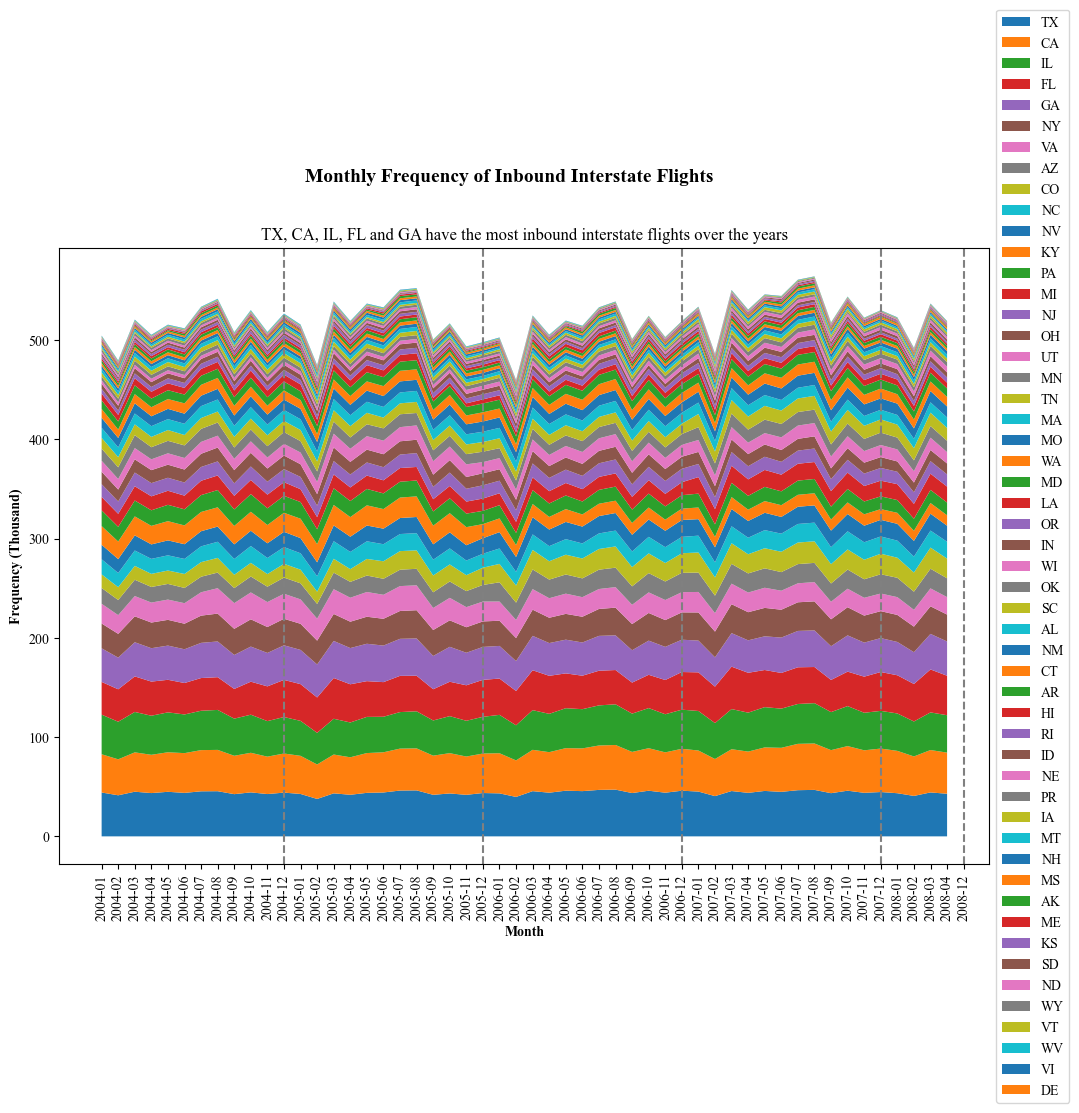

In [61]:
df = Q3_MonthlyFrequencyOfInboundByState.pivot_table(index='Month', columns='state', values='Frequency', aggfunc='sum')

state_order = df.sum().sort_values(ascending=False).index
df = df[state_order]
df_cumulative = df.cumsum(axis=1)
fig, ax = plt.subplots(figsize=(12,8))
for state in df.columns:
    ax.fill_between(df.index, df_cumulative[state] - df[state], df_cumulative[state], label=state, linewidth=0.5)
fig.suptitle('Monthly Frequency of Inbound Interstate Flights', fontsize=14, fontweight='bold', fontname='Times New Roman')
ax.set_title('TX, CA, IL, FL and GA have the most inbound interstate flights over the years', fontname='Times New Roman')
ax.set_xlabel('Month', fontweight='bold', fontname='Times New Roman')
ax.set_ylabel('Frequency (Thousand)', fontweight='bold', fontname='Times New Roman')
ax.tick_params(axis='x', rotation=90)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    ax.axvline(x=xc, color='grey', linestyle='--')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman') 
plt.show()

In [62]:
years = ["2004", "2005", "2006", "2007", "2008"]

for year in years:
    yearly_inbound_frequency = f"""SELECT airports.state, Year AS Year, COUNT() as Frequency,
                                   COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY flightdetails.Year) AS FLOAT) AS Percentage
                                   FROM flightdetails
                                   INNER JOIN airports ON flightdetails.Dest = airports.iata
                                   INNER JOIN airports a ON flightdetails.Origin = a.iata
                                   WHERE airports.state <> a.state AND Year = '{year}'
                                   GROUP BY airports.state, flightdetails.Year
                                   ORDER BY flightdetails.Year"""
    globals()[f"Q3_{year}FrequencyOfInboundState"] = pd.read_sql(yearly_inbound_frequency, conn)

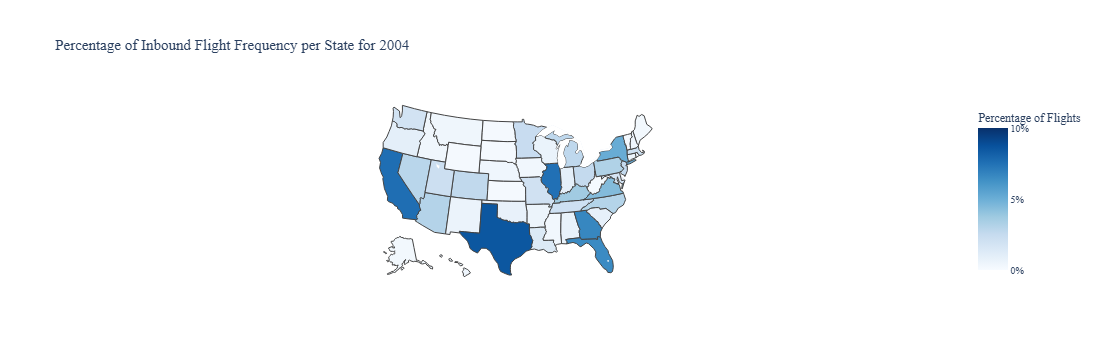

In [63]:
fig = px.choropleth(Q3_2004FrequencyOfInboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Inbound Flight Frequency per State for 2004')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

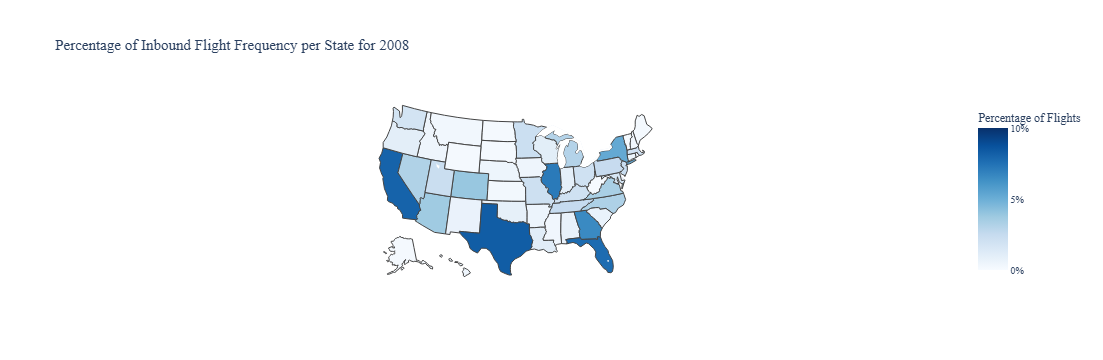

In [64]:
fig = px.choropleth(Q3_2008FrequencyOfInboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Inbound Flight Frequency per State for 2008')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

In [65]:
Q3_MonthlyFrequencyOfOutboundByState = pd.read_sql_query("""SELECT a.state, strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2)) AS Month, COUNT() as Frequency, COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY substr(flightdetails.CurrentDate, 4, 7)) AS FLOAT) AS Percentage
                                                           FROM flightdetails
                                                           INNER JOIN airports ON flightdetails.Dest = airports.iata
                                                           INNER JOIN airports a ON flightdetails.Origin = a.iata
                                                           WHERE airports.state <> a.state
                                                           GROUP BY a.state, substr(flightdetails.CurrentDate, 4, 7)
                                                           ORDER BY strftime('%Y-%m', substr(flightdetails.CurrentDate, 7, 4) || '-' || substr(flightdetails.CurrentDate, 4, 2) || '-' || substr(flightdetails.CurrentDate, 1, 2))""", conn)

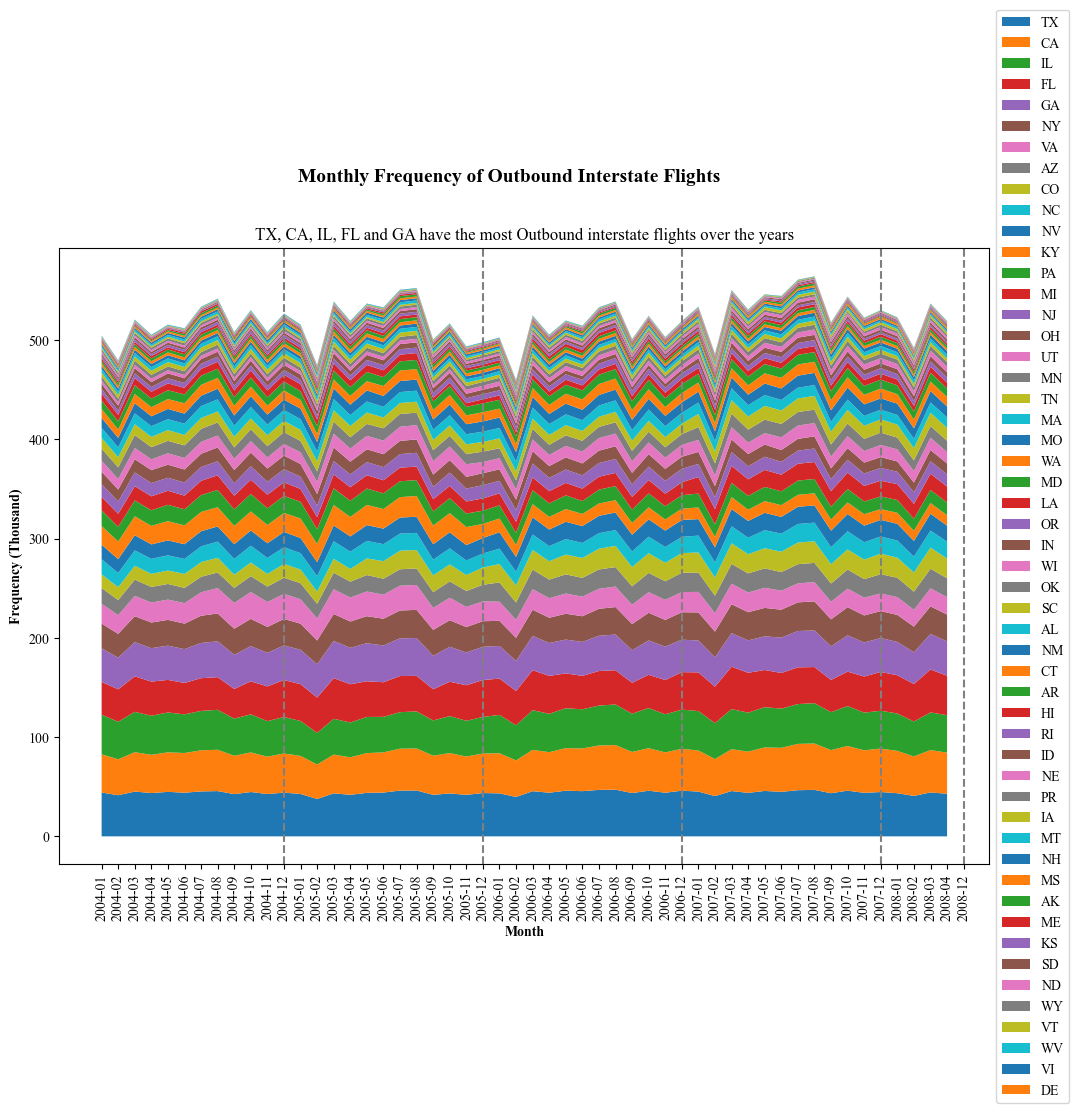

In [66]:
df = Q3_MonthlyFrequencyOfOutboundByState.pivot_table(index='Month', columns='state', values='Frequency', aggfunc='sum')

state_order = df.sum().sort_values(ascending=False).index
df = df[state_order]
df_cumulative = df.cumsum(axis=1)
fig, ax = plt.subplots(figsize=(12,8))
for state in df.columns:
    ax.fill_between(df.index, df_cumulative[state] - df[state], df_cumulative[state], label=state, linewidth=0.5)
fig.suptitle('Monthly Frequency of Outbound Interstate Flights', fontsize=14, fontweight='bold', fontname='Times New Roman')
ax.set_title('TX, CA, IL, FL and GA have the most Outbound interstate flights over the years', fontname='Times New Roman')
ax.set_xlabel('Month', fontweight='bold', fontname='Times New Roman')
ax.set_ylabel('Frequency (Thousand)', fontweight='bold', fontname='Times New Roman')
ax.tick_params(axis='x', rotation=90)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: '{:.0f}'.format(y/1000)))
for xc in ["2004-12", "2005-12", "2006-12", "2007-12", "2008-12"]:
    ax.axvline(x=xc, color='grey', linestyle='--')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.xticks(fontname='Times New Roman')
plt.yticks(fontname='Times New Roman') 
plt.show()

In [67]:
years = ["2004", "2005", "2006", "2007", "2008"]

for year in years:
    yearly_outbound_frequency = f"""SELECT a.state, Year AS Year, COUNT() as Frequency,
                                   COUNT() / CAST(SUM(COUNT(*)) OVER (PARTITION BY flightdetails.Year) AS FLOAT) AS Percentage
                                   FROM flightdetails
                                   INNER JOIN airports ON flightdetails.Dest = airports.iata
                                   INNER JOIN airports a ON flightdetails.Origin = a.iata
                                   WHERE airports.state <> a.state AND Year = '{year}'
                                   GROUP BY a.state, flightdetails.Year
                                   ORDER BY flightdetails.Year"""
    globals()[f"Q3_{year}FrequencyOfOutboundState"] = pd.read_sql(yearly_outbound_frequency, conn)

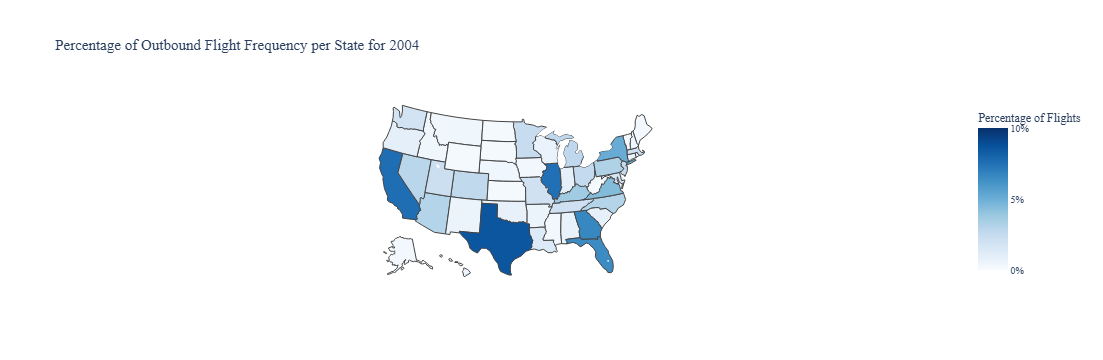

In [68]:
fig = px.choropleth(Q3_2004FrequencyOfOutboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Outbound Flight Frequency per State for 2004')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

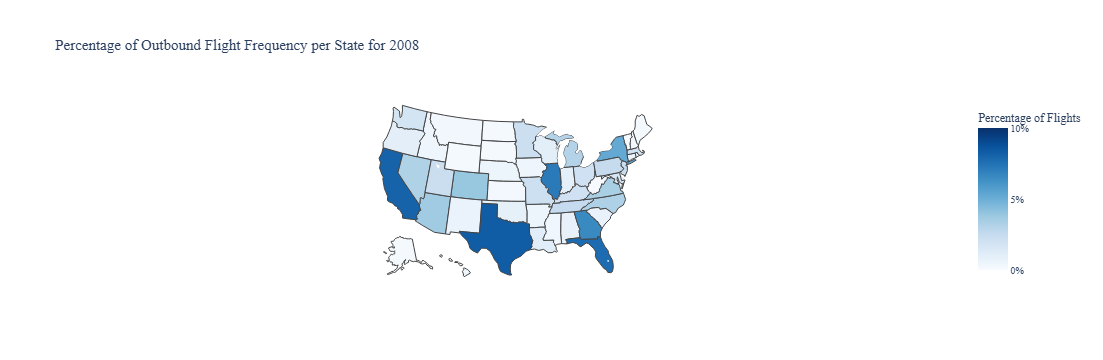

In [69]:
fig = px.choropleth(Q3_2008FrequencyOfOutboundState, 
                    locations='state', 
                    locationmode='USA-states',
                    color='Percentage',
                    scope='usa',
                    color_continuous_scale='Blues',
                    range_color=[0, 0.1],
                    title='Percentage of Outbound Flight Frequency per State for 2008')

fig.update_layout(title_font=dict(size=15, family='Times New Roman'),
                  font=dict(family='Times New Roman', size=10),
                  coloraxis_colorbar=dict(title=dict(text='Percentage of Flights'), 
                                          tickformat=".0%"),
                  geo=dict(scope='usa',projection=dict(type='albers usa')))

fig.show()

## Q4. Detecting cascading delays

In [10]:
try:
    conn.execute("ALTER TABLE flightdetails ADD COLUMN CurrentDate TEXT")
    conn.commit()
except:
    print("Column already exists.")

conn.execute("""
UPDATE flightdetails 
SET CurrentDate = Year || '-' || 
                  printf('%02d', Month) || '-' || 
                  printf('%02d', DayofMonth)
""")
conn.commit()

conn.execute("""
CREATE INDEX IF NOT EXISTS idx_cascading_search 
ON flightdetails (TailNum, CurrentDate, Origin, Dest)
""")
conn.commit()

In [11]:
conn.execute("""
CREATE INDEX IF NOT EXISTS idx_cascading_search 
ON flightdetails (TailNum, CurrentDate, Origin, Dest)
""")
conn.commit()

In [12]:
Q4_FrequencyOfCascadingDelays = pd.read_sql("""SELECT COUNT(*) AS TotalCascadingDelays
                                               FROM flightdetails AS f1
                                               JOIN flightdetails AS f2 ON f1.TailNum = f2.TailNum
                                               AND f1.CurrentDate = f2.CurrentDate
                                               AND f1.Dest = f2.Origin
                                               AND f1.CRSArrTime < f2.CRSDepTime
                                               AND f1.ArrDelay > 0
                                               AND f2.DepDelay > 0
                                               AND f2.ArrDelay > 0
                                               AND f2.LateAirCraftDelay > 0""", conn)

Q4_FrequencyOfCascadingDelays.head()

,TotalCascadingDelays
0,3355785


In [13]:
Q4_EntriesOfCascadingDelays = pd.read_sql_query("""SELECT f1.TailNum AS TailNum1, f1.TailNum AS TailNum2,
                                                f1.CurrentDate AS Date1, f2.CurrentDate AS Date2,
                                                f1.Origin AS Origin1, f1.Dest AS Dest1,
                                                f2.Origin AS Origin2, f2.Dest AS Dest2,
                                                f1.CRSArrTime AS S_ArrTime1, f1.ArrTime AS A_ArrTime1,
                                                f2.CRSDepTime AS S_DepTime1, f2.DepTime AS A_DepTime1,
                                                f2.CRSArrTime AS S_ArrTime2, f2.ArrTime AS A_ArrTime2,
                                                f1.ArrDelay AS ArrDelay1, f2.DepDelay AS DepDelay1, f2.ArrDelay AS ArrDelay2,
                                                f2.CarrierDelay AS C_Delay2, f2.NASDelay AS NAS_Delay2, f2.LateAircraftDelay AS LA_Delay2,
                                                f2.WeatherDelay AS W_Delay, f2.SecurityDelay AS D_Delay
                                                FROM flightdetails AS f1
                                                JOIN flightdetails AS f2 ON f1.TailNum = f2.TailNum
                                                AND f1.CurrentDate = f2.CurrentDate
                                                AND f1.Dest = f2.Origin
                                                AND f1.CRSArrTime < f2.CRSDepTime
                                                AND f1.ArrDelay > 0
                                                AND f2.DepDelay > 0
                                                AND f2.ArrDelay > 0
                                                AND f2.LateAircraftDelay > 0
                                                ORDER BY strftime('%Y-%m', substr(f1.CurrentDate, 7, 4) || '-' || substr(f1.CurrentDate, 4, 2) || '-' || substr(f1.CurrentDate, 1, 2))""", conn)

Q4_EntriesOfCascadingDelays.head()

,TailNum1,TailNum2,Date1,Date2,Origin1,Dest1,Origin2,Dest2,S_ArrTime1,A_ArrTime1,...,S_ArrTime2,A_ArrTime2,ArrDelay1,DepDelay1,ArrDelay2,C_Delay2,NAS_Delay2,LA_Delay2,W_Delay,D_Delay
0,N819UA,N819UA,2004-01-05,2004-01-05,ORD,PDX,PDX,SFO,1725,1855.0,...,2053,2137.0,90.0,46.0,44.0,30,0,14,0,0
1,N805UA,N805UA,2004-01-10,2004-01-10,ORD,PDX,PDX,LAX,1744,1831.0,...,2109,2126.0,47.0,13.0,17.0,7,4,6,0,0
2,N529UA,N529UA,2004-01-23,2004-01-23,ORD,PDX,PDX,SFO,1732,1848.0,...,2050,2114.0,76.0,13.0,24.0,0,11,13,0,0
3,N576UA,N576UA,2004-01-29,2004-01-29,ORD,PDX,PDX,SFO,1732,1917.0,...,2050,2249.0,105.0,46.0,119.0,0,73,46,0,0
4,N394UA,N394UA,2004-01-25,2004-01-25,OKC,DEN,DEN,BOI,1915,1958.0,...,2146,4.0,43.0,50.0,138.0,0,88,43,7,0


## Q5a. Coursework model (contains target leakage)

The features below include `DepTime`, `DepDelay`, `AirTime`, `TaxiIn` and `TaxiOut`. These are only known once the flight has left (or landed), and departure delay almost decides whether the arrival is 15+ minutes late. That is **target leakage**: the models score AUC 0.94–0.98 because they are partly told the answer. A sign of it is that plain logistic regression does about as well as random forest.

The split is also random rather than by time, so the models train on flights from the same days they are tested on. Both problems are fixed in Q5b.

In [10]:
LearningSample = pd.read_sql_query("""SELECT Year, Month, DayofMonth, DayofWeek, DepTime, CRSDepTime, AirTime, Distance, DepDelay, TaxiIn, TaxiOut, 
                                      CASE WHEN ArrDelay < 15 THEN 0 ELSE 1 END AS Delayed
                                      FROM flightdetails
                                      ORDER BY RANDOM() LIMIT 100000""", conn)

In [11]:
LearningSample.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,AirTime,Distance,DepDelay,TaxiIn,TaxiOut,Delayed
0,2004,11,6,6,801.0,800,243.0,2139,1.0,8.0,15.0,0
1,2005,11,20,7,2100.0,1915,91.0,581,105.0,11.0,16.0,1
2,2004,12,4,6,616.0,620,61.0,474,-4.0,7.0,11.0,0
3,2006,11,24,5,2351.0,2359,38.0,256,-8.0,2.0,15.0,0
4,2005,11,14,1,2208.0,2210,284.0,2586,-2.0,8.0,11.0,0


In [12]:
features = ['Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'CRSDepTime', 'AirTime', 'Distance', 'DepDelay', 'TaxiIn', 'TaxiOut']
X = LearningSample[features].copy()
y = LearningSample['Delayed'].copy()

In [13]:
y.head()

0    0
1    1
2    0
3    0
4    0
Name: Delayed, dtype: int64

In [14]:
numerical_features = ['DepTime', 'CRSDepTime', 'AirTime', 'Distance', 'DepDelay', 'TaxiIn', 'TaxiOut']

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer()),
    ('scaler', StandardScaler())])

categorical_features = ['Year', 'Month', 'DayofMonth', 'DayOfWeek']

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer()),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

data_transformer = ColumnTransformer(
    transformers=[
        ('numerical', numerical_transformer, numerical_features),
        ('categorical', categorical_transformer, categorical_features)])

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,random_state=1)

In [16]:
param_grid = {
    'data_transformer__numerical__imputer__strategy': ['mean', 'median'],
    'data_transformer__categorical__imputer__strategy': ['constant','most_frequent']
}

In [36]:
pipe_lr = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_lr', LogisticRegression(max_iter=10000, penalty=None)) 
])

param_grid = {
    'pipe_lr__solver': ['lbfgs', 'saga']
}

grid_lr = GridSearchCV(pipe_lr, param_grid=param_grid)
grid_lr.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('data_transformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['DepTime',
                                                                          'CRSDepTime',
                                                                          'AirTime',
                                                                          'Distance',
                                                                          'DepDelay',
                                                                          'TaxiIn',
                                                                          'TaxiOut']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Year',
                                                                          'Month',
                                                                          'DayofMonth',
                                                                          'DayOfWeek'])])),
                                       ('pipe_lr',
                                        LogisticRegression(max_iter=10000,
                                                           penalty=None))]),
             param_grid={'pipe_lr__solver': ['lbfgs', 'saga']})

In [33]:
pipe_gdb = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_gdb', GradientBoostingClassifier(random_state=2))
])

param_grid = {
    'pipe_gdb__n_estimators': [100, 150],
    'pipe_gdb__learning_rate': [0.1, 0.05],
    'pipe_gdb__max_depth': [3, 5]
}

grid_gdb = GridSearchCV(pipe_gdb, param_grid=param_grid, n_jobs=-1)
grid_gdb.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('data_transformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['DepTime',
                                                                          'CRSDepTime',
                                                                          'AirTime',
                                                                          'Distance',
                                                                          'DepDelay',
                                                                          'TaxiIn',
                                                                          'TaxiOut']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Year',
                                                                          'Month',
                                                                          'DayofMonth',
                                                                          'DayOfWeek'])])),
                                       ('pipe_gdb',
                                        GradientBoostingClassifier(random_state=2))]),
             n_jobs=-1,
             param_grid={'pipe_gdb__learning_rate': [0.1, 0.05],
                         'pipe_gdb__max_depth': [3, 5],
                         'pipe_gdb__n_estimators': [100, 150]})

In [25]:
pipe_plr = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_plr', LogisticRegression(penalty='l1', max_iter=10000, tol=0.01, solver='saga'))
])

param_grid = {
    'pipe_plr__C': [0.1, 1.0, 10.0]
}

grid_plr = GridSearchCV(pipe_plr, param_grid=param_grid)
grid_plr.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('data_transformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['DepTime',
                                                                          'CRSDepTime',
                                                                          'AirTime',
                                                                          'Distance',
                                                                          'DepDelay',
                                                                          'TaxiIn',
                                                                          'TaxiOut']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Year',
                                                                          'Month',
                                                                          'DayofMonth',
                                                                          'DayOfWeek'])])),
                                       ('pipe_plr',
                                        LogisticRegression(max_iter=10000,
                                                           penalty='l1',
                                                           solver='saga',
                                                           tol=0.01))]),
             param_grid={'pipe_plr__C': [0.1, 1.0, 10.0]})

In [27]:
pipe_tree = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_tree', DecisionTreeClassifier(random_state=0))
])

param_grid = {
    'pipe_tree__max_depth': [5, 10, 20],
    'pipe_tree__min_samples_split': [2, 10],
    'pipe_tree__criterion': ['gini', 'entropy']
}

grid_tree = GridSearchCV(pipe_tree, param_grid=param_grid)
grid_tree.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('data_transformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['DepTime',
                                                                          'CRSDepTime',
                                                                          'AirTime',
                                                                          'Distance',
                                                                          'DepDelay',
                                                                          'TaxiIn',
                                                                          'TaxiOut']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Year',
                                                                          'Month',
                                                                          'DayofMonth',
                                                                          'DayOfWeek'])])),
                                       ('pipe_tree',
                                        DecisionTreeClassifier(random_state=0))]),
             param_grid={'pipe_tree__criterion': ['gini', 'entropy'],
                         'pipe_tree__max_depth': [5, 10, 20],
                         'pipe_tree__min_samples_split': [2, 10]})

In [29]:
pipe_rf = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_rf', RandomForestClassifier(random_state=0))
])

param_grid = {
    'pipe_rf__n_estimators': [100, 200],
    'pipe_rf__max_depth': [10, 20],
    'pipe_rf__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(pipe_rf, param_grid=param_grid, n_jobs=-1)
grid_rf.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('data_transformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['DepTime',
                                                                          'CRSDepTime',
                                                                          'AirTime',
                                                                          'Distance',
                                                                          'DepDelay',
                                                                          'TaxiIn',
                                                                          'TaxiOut']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Year',
                                                                          'Month',
                                                                          'DayofMonth',
                                                                          'DayOfWeek'])])),
                                       ('pipe_rf',
                                        RandomForestClassifier(random_state=0))]),
             n_jobs=-1,
             param_grid={'pipe_rf__max_depth': [10, 20],
                         'pipe_rf__min_samples_split': [2, 5],
                         'pipe_rf__n_estimators': [100, 200]})

In [31]:
pipe_svm = Pipeline(steps=[
    ('data_transformer', data_transformer),
    ('pipe_svm', LinearSVC(random_state=0, max_iter=10000, tol=0.01))
])

param_grid = {
    'pipe_svm__C': [0.1, 1.0, 10.0],
    'pipe_svm__loss': ['hinge', 'squared_hinge']
}

grid_svm = GridSearchCV(pipe_svm, param_grid=param_grid)
grid_svm.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('data_transformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['DepTime',
                                                                          'CRSDepTime',
                                                                          'AirTime',
                                                                          'Distance',
                                                                          'DepDelay',
                                                                          'TaxiIn',
                                                                          'TaxiOut']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer()),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Year',
                                                                          'Month',
                                                                          'DayofMonth',
                                                                          'DayOfWeek'])])),
                                       ('pipe_svm',
                                        LinearSVC(max_iter=10000,
                                                  random_state=0, tol=0.01))]),
             param_grid={'pipe_svm__C': [0.1, 1.0, 10.0],
                         'pipe_svm__loss': ['hinge', 'squared_hinge']})

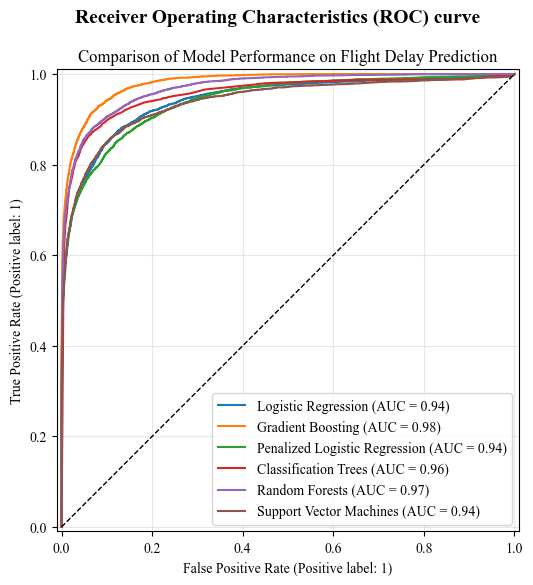

In [38]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(grid_lr, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(grid_gdb, X_test, y_test, ax=ax, name='Gradient Boosting')
RocCurveDisplay.from_estimator(grid_plr, X_test, y_test, ax=ax, name='Penalized Logistic Regression')
RocCurveDisplay.from_estimator(grid_tree, X_test, y_test, ax=ax, name='Classification Trees')
RocCurveDisplay.from_estimator(grid_rf, X_test, y_test, ax=ax, name='Random Forests')
RocCurveDisplay.from_estimator(grid_svm, X_test, y_test, ax=ax, name='Support Vector Machines')

plt.plot([0, 1], [0, 1], color='black', lw=1, linestyle='--')
plt.suptitle("Receiver Operating Characteristics (ROC) curve", fontsize=14, fontweight='bold', fontname='Times New Roman')
plt.title("Comparison of Model Performance on Flight Delay Prediction", fontname='Times New Roman')
plt.grid(alpha=0.3)
plt.show()

## Q5b. Leakage-free model (v2)

`src/model_v2.py` rebuilds the model with only what is known before departure: scheduled departure and arrival hour, scheduled flight time, distance, month, weekday, carrier, origin, destination and aircraft age. It trains on 2004–2007 and tests on 2008 (the 2008 file covers January to April), and runs the leaky feature set beside it so the gap is visible.

Run it with:

```bash
python src/model_v2.py --db data/Fly.db
```

Results from the run reported in the README (1% sample: 282,428 training flights, 23,131 test flights):

| Model | Features | Test AUC (Jan–Apr 2008) |
|---|---|---|
| Logistic regression | Pre-departure | 0.627 |
| Gradient boosting | Pre-departure | **0.641** |
| Gradient boosting | + departure delay, taxi, air time (leaky) | 0.997 |

Predicting a delay from the schedule alone is hard: about 0.64 is a modest but real signal. Adding departure delay and the other post-departure fields lifts it to 0.997, and that gap is the leakage.